# RDST with a cost-sensitive loss: missing a rejected batch costs more

Same model and splits as `04_train_rdst_process_A.ipynb` (A: 70/30) and `05_train_rdst_process_B.ipynb` (B: 50/50),
with one change in the ridge loss.

* Before: `class_weight="balanced"`, so each class carries the same total weight (process A: rejected 2.0, accepted 0.67 per batch).
* Now: balanced weights, **then every rejected batch × `REJECTED_COST` (= 2)**. Errors on rejected batches count twice as much
  in the loss, so the model trades a few more false alarms for fewer missed rejections.
* Ridge has a squared loss on ±1 targets, so the weight scales *every* error on a rejected batch, not only outright
  misclassifications. Doubling it is the ridge equivalent of "a missed rejected batch costs double".
* The weighting is used both in the 4-fold CV that picks alpha and the spread weight, and in the final fit.
  The RDST shapelets do not depend on it (same seed, so the same shapelets as before).
* Output: `models/rdst_process_{A,B}_seed0_cost2.pkl` + `.json`. The earlier models are not touched.
* The notebook ends with the **test-set scores** (metrics, confusion matrix, score of every test batch) and the
  **training curves**. Ridge has no epochs, so the curves are (1) a validation curve: CV F1 over the ridge strength alpha
  for each spread weight, the search that picks the settings, and (2) a learning curve: training and CV F1 as the
  number of training batches grows.

In [1]:
import json
import warnings
from pathlib import Path

import cloudpickle
import matplotlib.pyplot as plt
import nbformat
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

# run the setup + model cells (1 and 2) of the RDST notebook in this namespace
rdst_nb = nbformat.read("03_rdst_spread_seed0.ipynb", as_version=4)
for i in (1, 2):
    exec(rdst_nb.cells[i].source)

warnings.filterwarnings("ignore", message="The least populated class")  # process B: 3 rejected < 4 CV folds

/home/renku/work/input-data/Project 2 - BRPMM


In [2]:
REJECTED_COST = 2.0
_SkRidge = RidgeClassifier


class CostSensitiveRidge(_SkRidge):
    """Ridge with balanced class weights, then rejected (label 1) batches weighted REJECTED_COST times more."""

    def fit(self, X, y, sample_weight=None):
        w = compute_sample_weight("balanced", y) * np.where(y == 1, REJECTED_COST, 1.0)
        self.class_weight = None  # all weighting is in w
        return super().fit(X, y, sample_weight=w)


# Model.fit and mean_f1 (from the RDST notebook) look up RidgeClassifier here, so both now use the new loss
RidgeClassifier = CostSensitiveRidge

## Train and save (one model per process)

In [3]:
SPLITS = {"A": 0.30, "B": 0.50}  # test fraction per process, stratified by label, random_state=42
out = Path("models")
out.mkdir(exist_ok=True)
runs = {}

for p, test_size in SPLITS.items():
    folder = DATA_DIR / f"process {p}" / "calibration data"
    batches = load_batches(folder / "calibration_data.csv")
    labels = pd.read_csv(folder / "calibration_labels.csv")
    is_rejected = labels.set_index("batch_id").label.eq("rejected").astype(int)

    train_ids, test_ids = train_test_split(labels.batch_id, test_size=test_size, random_state=42, stratify=labels.label)
    train_ids, test_ids = train_ids.sort_index(), test_ids.sort_index()
    print(f"process {p}: train {len(train_ids)} ({is_rejected[train_ids].sum()} rejected), "
          f"test {len(test_ids)} ({is_rejected[test_ids].sum()} rejected)")

    train_series, train_spread = inputs(batches, train_ids)
    test_series, test_spread = inputs(batches, test_ids)
    y_train, y_test = is_rejected[train_ids].to_numpy(), is_rejected[test_ids].to_numpy()
    model = Model().fit(train_series, train_spread, y_train)

    # features in the model's own space (RDST + spread, scaled and weighted), kept for the scores and curves
    shapes_train = model._clean(model.rdst.transform(model._scale(train_series)))
    shapes_test = model._clean(model.rdst.transform(model._scale(test_series)))
    X_test = model._join(shapes_test, test_spread, model.weight)
    pred = model.ridge.predict(X_test)
    assert (pred == model.predict(test_series, test_spread)).all()

    name = f"rdst_process_{p}_seed0_cost{REJECTED_COST:g}"
    with open(out / f"{name}.pkl", "wb") as f:
        cloudpickle.dump(model, f)
    with open(out / f"{name}.pkl", "rb") as f:  # check the saved model
        assert (cloudpickle.load(f).predict(test_series, test_spread) == pred).all()
    print(f"  saved {name}.pkl\n")

    runs[p] = dict(model=model, name=name, test_size=test_size, train_ids=train_ids, test_ids=test_ids,
                   shapes_train=shapes_train, spread_train=train_spread, y_train=y_train,
                   X_test=X_test, y_test=y_test, pred=pred, score=model.ridge.decision_function(X_test))

process A: train 112 (28 rejected), test 49 (12 rejected)


spread weight 0.5, alpha 0.001, CV F1 inside training 0.801


  saved rdst_process_A_seed0_cost2.pkl



process B: train 20 (3 rejected), test 20 (2 rejected)


spread weight 2.0, alpha 0.001, CV F1 inside training 0.750


  saved rdst_process_B_seed0_cost2.pkl



## Test-set scores

Each model is scored once, on its own held-out test batches. These were not used for training or for picking the settings.
"Before" is the earlier balanced-weight model (`rdst_process_{A,B}_seed0.json`) on the same test batches.

In [4]:
def metrics(true, pred):
    return {"f1_rejected": f1_score(true, pred, zero_division=0), "precision": precision_score(true, pred, zero_division=0),
            "recall": recall_score(true, pred, zero_division=0), "accuracy": accuracy_score(true, pred),
            "rejected_caught": int(((pred == 1) & (true == 1)).sum()), "rejected_total": int(true.sum()),
            "false_alarms": int(((pred == 1) & (true == 0)).sum()), "accepted_total": int((true == 0).sum())}

rows = []
for p, r in runs.items():
    r["metrics"] = metrics(r["y_test"], r["pred"])
    meta = {"process": p, "seed": SEED, "length": LENGTH, "rejected_cost": REJECTED_COST,
            "split": {"test_size": r["test_size"], "random_state": 42, "stratify": "label"},
            "spread_weight": r["model"].weight, "alpha": float(r["model"].alpha),
            "train_ids": list(r["train_ids"]), "test_ids": list(r["test_ids"]), "test_metrics": r["metrics"]}
    (out / f"{r['name']}.json").write_text(json.dumps(meta, indent=2, default=float))
    before = json.loads((out / f"rdst_process_{p}_seed0.json").read_text())["test_metrics"]
    rows += [{"process": p, "loss": "balanced (before)", **before},
             {"process": p, "loss": f"rejected x{REJECTED_COST:g} (now)", **r["metrics"]}]

pd.DataFrame(rows).set_index(["process", "loss"]).round(3)

f1_rejected  precision  recall  accuracy  \
process loss                                                          
A       balanced (before)        0.833      0.833   0.833     0.918   
        rejected x2 (now)        0.833      0.833   0.833     0.918   
B       balanced (before)        1.000      1.000   1.000     1.000   
        rejected x2 (now)        1.000      1.000   1.000     1.000   

                           rejected_caught  rejected_total  false_alarms  \
process loss                                                               
A       balanced (before)               10              12             2   
        rejected x2 (now)               10              12             2   
B       balanced (before)                2               2             0   
        rejected x2 (now)                2               2             0   

                           accepted_total  
process loss                               
A       balanced (before)              37  
        rejected x2 (now)              37  
B       balanced (before)              18  
        rejected x2 (now)              18

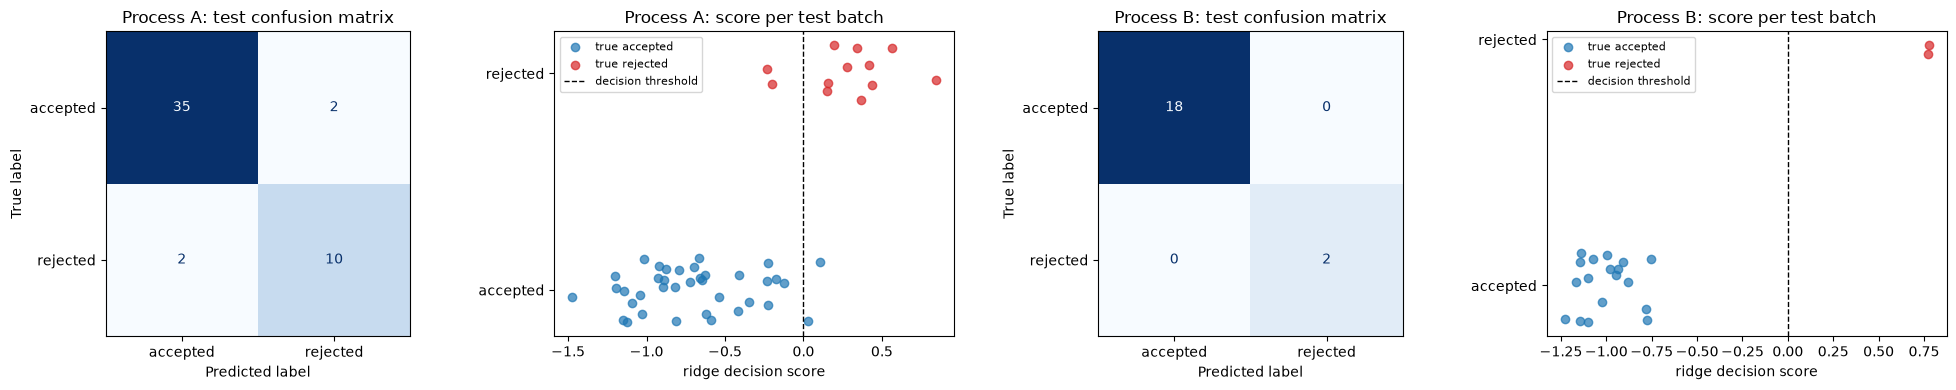

In [5]:
fig, axes = plt.subplots(1, 2 * len(runs), figsize=(5 * 2 * len(runs), 4))
for k, (p, r) in enumerate(runs.items()):
    ConfusionMatrixDisplay(confusion_matrix(r["y_test"], r["pred"], labels=[0, 1]),
                           display_labels=["accepted", "rejected"]).plot(ax=axes[2 * k], colorbar=False, cmap="Blues")
    axes[2 * k].set_title(f"Process {p}: test confusion matrix")

    # ridge score of every test batch: above 0 = predicted rejected
    ax = axes[2 * k + 1]
    rng = np.random.default_rng(0)
    for cls, color, lab in [(0, "tab:blue", "accepted"), (1, "tab:red", "rejected")]:
        s = r["score"][r["y_test"] == cls]
        ax.scatter(s, cls + rng.uniform(-0.15, 0.15, len(s)), color=color, alpha=0.7, label=f"true {lab}")
    ax.axvline(0, color="k", ls="--", lw=1, label="decision threshold")
    ax.set_yticks([0, 1], ["accepted", "rejected"])
    ax.set_xlabel("ridge decision score")
    ax.set_title(f"Process {p}: score per test batch")
    ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## Training curves

**Validation curve:** this redoes the search inside `Model.fit`. For every spread weight and alpha it shows the
4-fold CV F1 of "rejected" (with the cost-sensitive loss), plus the F1 on the training batches themselves for the
chosen spread weight. The star marks the chosen setting. A big gap between training and CV F1 means overfitting.

**Learning curve:** with the chosen alpha and spread weight, training and CV F1 as the number of training batches
grows (stratified subsets, 5 repeats per fold). One shortcut: the RDST shapelets come from the full training set
rather than being refitted for each subset, since each refit takes minutes. The test set is not involved.

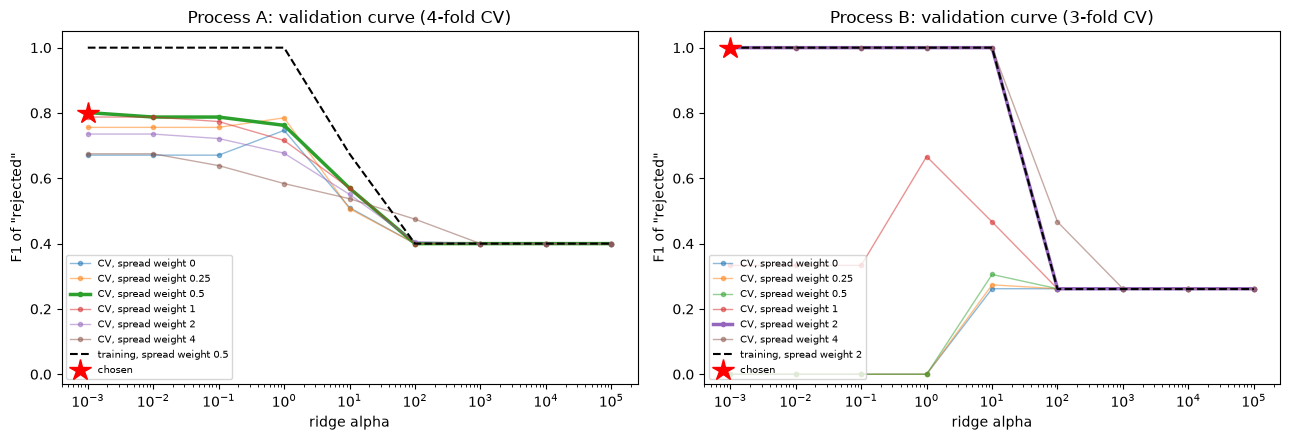

In [6]:
def cv_folds(y):
    k = int(min(4, np.bincount(y).min()))  # process B has only 3 rejected training batches -> 3 folds
    return list(StratifiedKFold(k, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))


def fit_score(X, y, alpha, fit_idx, eval_idx):
    clf = RidgeClassifier(alpha=alpha).fit(X[fit_idx], y[fit_idx])
    return f1_score(y[eval_idx], clf.predict(X[eval_idx]), zero_division=0)


fig, axes = plt.subplots(1, len(runs), figsize=(6.5 * len(runs), 4.5), squeeze=False)
for ax, (p, r) in zip(axes[0], runs.items()):
    m, y = r["model"], r["y_train"]
    folds = cv_folds(y)
    for w in SPREAD_WEIGHTS:
        X = m._join(r["shapes_train"], r["spread_train"], w)
        cv = [np.mean([fit_score(X, y, a, tr, va) for tr, va in folds]) for a in ALPHAS]
        ax.plot(ALPHAS, cv, marker="o", ms=3, lw=2.5 if w == m.weight else 1, alpha=1 if w == m.weight else 0.5,
                label=f"CV, spread weight {w:g}")
    X = m._join(r["shapes_train"], r["spread_train"], m.weight)
    every = np.arange(len(y))
    ax.plot(ALPHAS, [fit_score(X, y, a, every, every) for a in ALPHAS], "k--", label=f"training, spread weight {m.weight:g}")
    ax.plot(m.alpha, np.mean([fit_score(X, y, m.alpha, tr, va) for tr, va in folds]), "r*", ms=16, label="chosen")
    ax.set(xscale="log", xlabel="ridge alpha", ylabel='F1 of "rejected"', ylim=(-0.03, 1.05),
           title=f"Process {p}: validation curve ({len(folds)}-fold CV)")
    ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

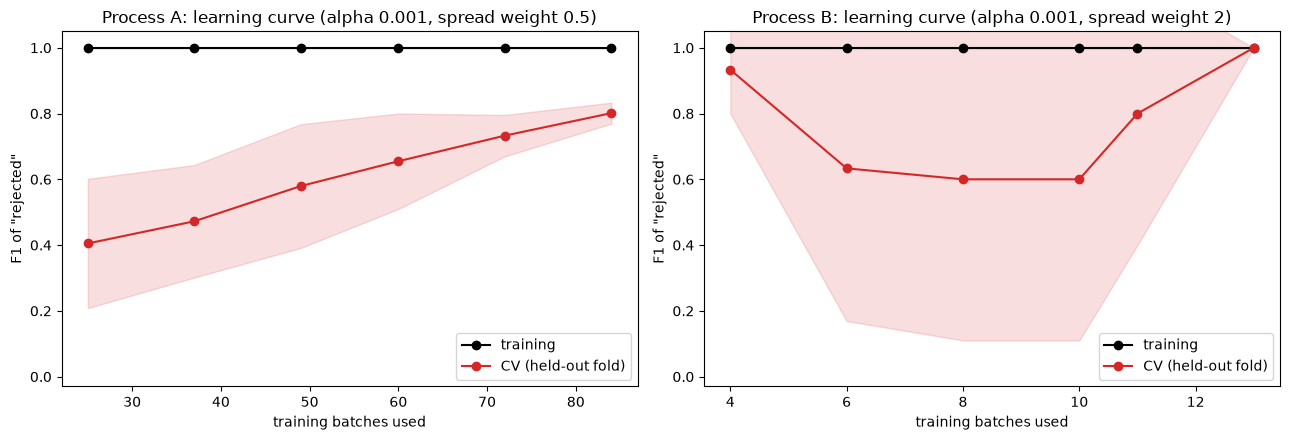

In [7]:
fig, axes = plt.subplots(1, len(runs), figsize=(6.5 * len(runs), 4.5), squeeze=False)
for ax, (p, r) in zip(axes[0], runs.items()):
    m, y = r["model"], r["y_train"]
    X = m._join(r["shapes_train"], r["spread_train"], m.weight)
    folds = cv_folds(y)
    fracs = np.linspace(0.3, 1.0, 6)
    train_f1, cv_f1, sizes = [], [], []
    for frac in fracs:
        tr_s, va_s = [], []
        for tr, va in folds:
            repeats = 1 if frac == 1.0 else 5
            for rep in range(repeats):
                if frac < 1.0:
                    sub, _ = train_test_split(tr, train_size=frac, stratify=y[tr], random_state=rep)
                else:
                    sub = tr
                if y[sub].sum() == 0:  # need at least one rejected batch to fit
                    continue
                tr_s.append(fit_score(X, y, m.alpha, sub, sub))
                va_s.append(fit_score(X, y, m.alpha, sub, va))
        sizes.append(int(round(frac * np.mean([len(tr) for tr, _ in folds]))))
        train_f1.append((np.mean(tr_s), np.std(tr_s)))
        cv_f1.append((np.mean(va_s), np.std(va_s)))
    for vals, color, lab in [(train_f1, "k", "training"), (cv_f1, "tab:red", "CV (held-out fold)")]:
        mu, sd = np.array(vals).T
        ax.plot(sizes, mu, marker="o", color=color, label=lab)
        ax.fill_between(sizes, mu - sd, mu + sd, color=color, alpha=0.15)
    ax.set(xlabel="training batches used", ylabel='F1 of "rejected"', ylim=(-0.03, 1.05),
           title=f"Process {p}: learning curve (alpha {m.alpha:g}, spread weight {m.weight:g})")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()